# VisionQ AI

This notebook sends an image and a text question to a vision-capable Groq model.

- Load your API key from `.env`
- Convert an image to Base64
- Send image + question to a multimodal LLM
- Read the model's answer

In [1]:
import base64
import mimetypes
import os

import ipywidgets as widgets
from IPython.display import display, Image

from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage

In [2]:
load_dotenv()

model_name = os.getenv("GROQ_MODEL")

llm = ChatGroq(
    model=model_name,
    temperature=0
)

## Choose an image

- Put an image (PNG, JPG, or WebP)

For example, use a photo of a question paper or a page from your notes.

In [3]:
image_upload = widgets.FileUpload(
    accept="image/png,image/jpeg,image/webp",
    multiple=False,
    description="Upload Image"
)

display(image_upload)

FileUpload(value=(), accept='image/png,image/jpeg,image/webp', description='Upload Image')

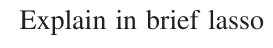

Uploaded: sample_question_2.png


In [4]:
if not image_upload.value:
    print("Please upload an image first.")

else:
    if isinstance(image_upload.value, dict): #isinstance() is Built-In function used to check wheather the image_upload is of dict type.
        uploaded_file = list(image_upload.value.values())[0]
    else:
        uploaded_file = image_upload.value[0]

    image_bytes = uploaded_file["content"]
    image_name = uploaded_file["name"]

    display(Image(data=image_bytes))
    print(f"Uploaded: {image_name}")

In [5]:
if image_upload.value:
    mime_type, _ = mimetypes.guess_type(image_name)

    if mime_type not in ["image/png", "image/jpeg", "image/webp"]:
        raise ValueError("Unsupported image format.")

    image_b64 = base64.b64encode(image_bytes).decode("utf-8")

    image_url = f"data:{mime_type};base64,{image_b64}"

    print("Image converted to Base64 successfully.")
else:
    print("Please upload an image first.")

Image converted to Base64 successfully.


In [7]:
question = "Solve the questions shown in this image step by step."

message = HumanMessage(
    content=[
        {"type": "text", "text": question},
        {"type": "image_url", "image_url": {"url": image_url}}
    ]
)

response = llm.invoke(
    [message],
    max_tokens=800
)

print(response.content)

Based on the image provided, the question is:

> **Explain in brief lasso**

---

### ✅ Brief Explanation of Lasso:

**Lasso** (Least Absolute Shrinkage and Selection Operator) is a **regularized regression method** used for both **feature selection** and **model simplification**.

#### Key Points:

1. **Purpose**:
   - Prevents overfitting by adding a penalty to the size of coefficients.
   - Performs automatic feature selection by shrinking some coefficients exactly to zero.

2. **Penalty Term**:
   - Adds an **L1 penalty** (sum of absolute values of coefficients) to the loss function:
     \[
     \text{Loss} = \text{Residual Sum of Squares} + \lambda \sum_{j=1}^{p} |\beta_j|
     \]
     where \( \lambda \geq 0 \) controls the amount of regularization.

3. **Effect**:
   - As \( \lambda \) increases, more coefficients are driven to zero → simpler model.
   - Useful when you have many features and suspect only a few are important.

4. **Use Cases**:
   - High-dimensional data (many 